# Exploratory Data Analysis — visualizations
Charts required by the presentation: flight number and payload by launch site/orbit, success by orbit, yearly trend.

In [1]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from pathlib import Path
D=Path('data');O=Path('outputs');O.mkdir(exist_ok=True)
df=pd.read_csv(D/'dataset_part_2.csv');print(df.columns.tolist())
site='LaunchSite' if 'LaunchSite' in df else 'LaunchSite'
payload='PayloadMass' if 'PayloadMass' in df else 'PayloadMass'
flight='FlightNumber' if 'FlightNumber' in df else 'FlightNumber'
orb='Orbit'
for col in [site,payload,flight,orb,'Class']:
    if col not in df: raise KeyError(f'Missing {col}: adapt the source dataset mapping')

['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']


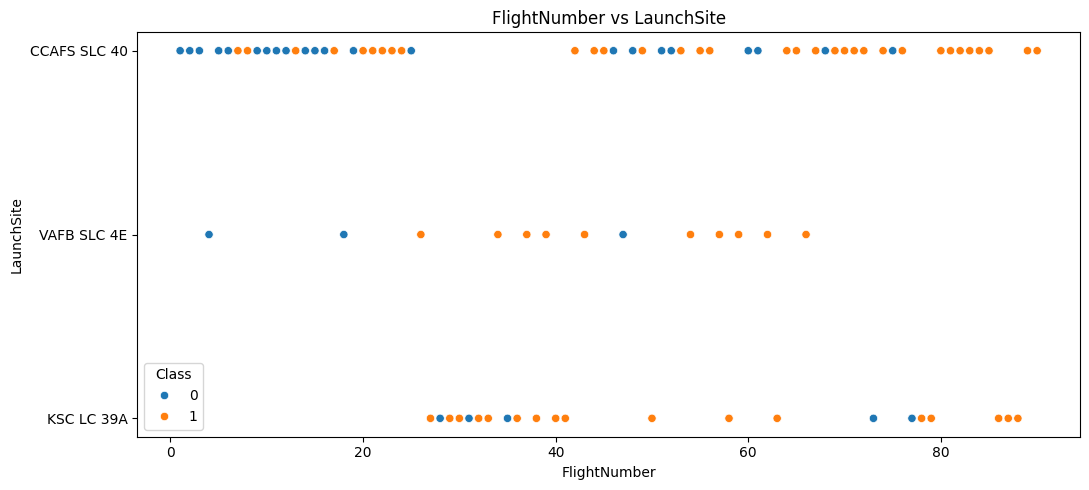

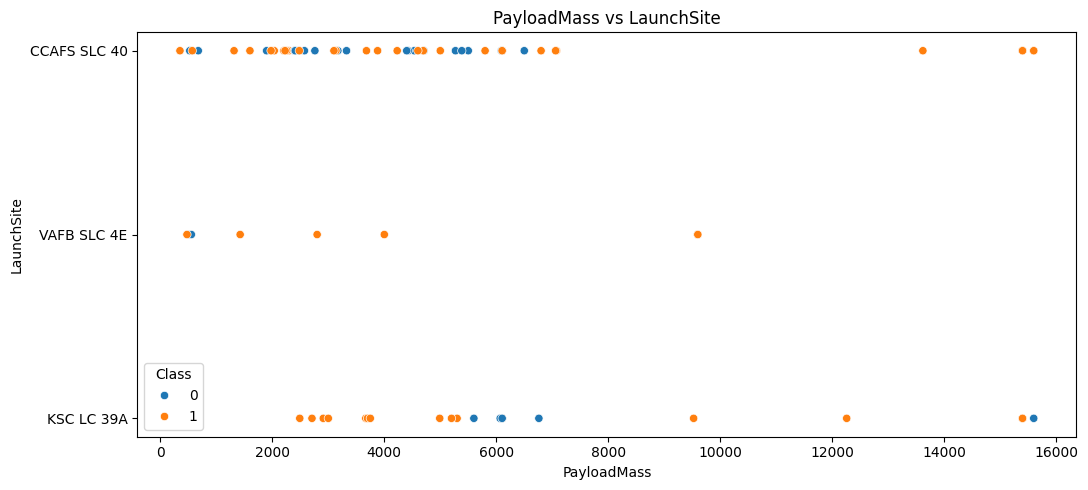

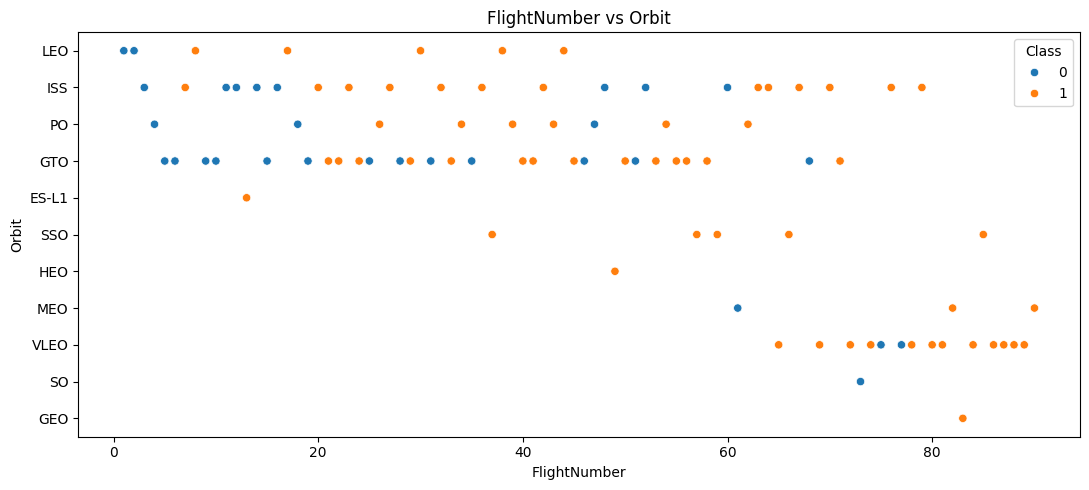

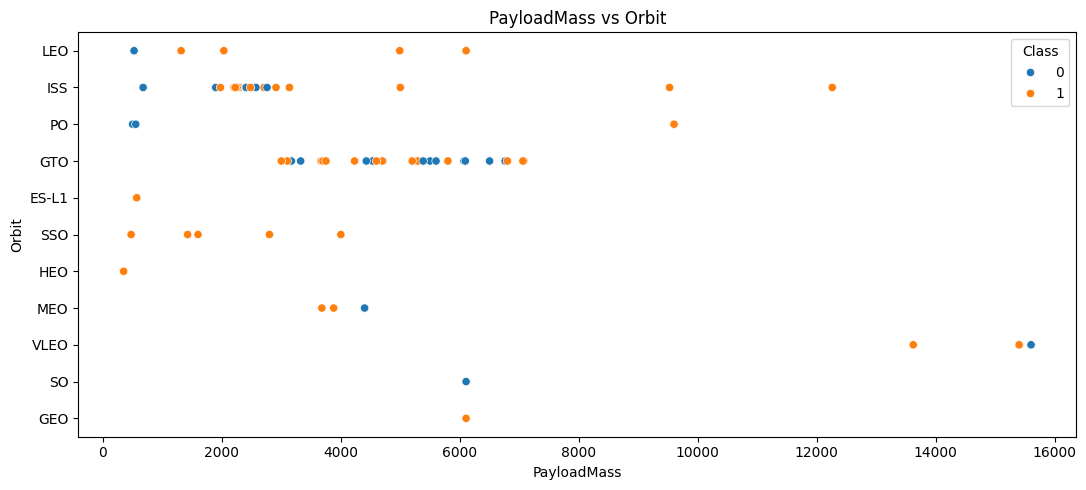

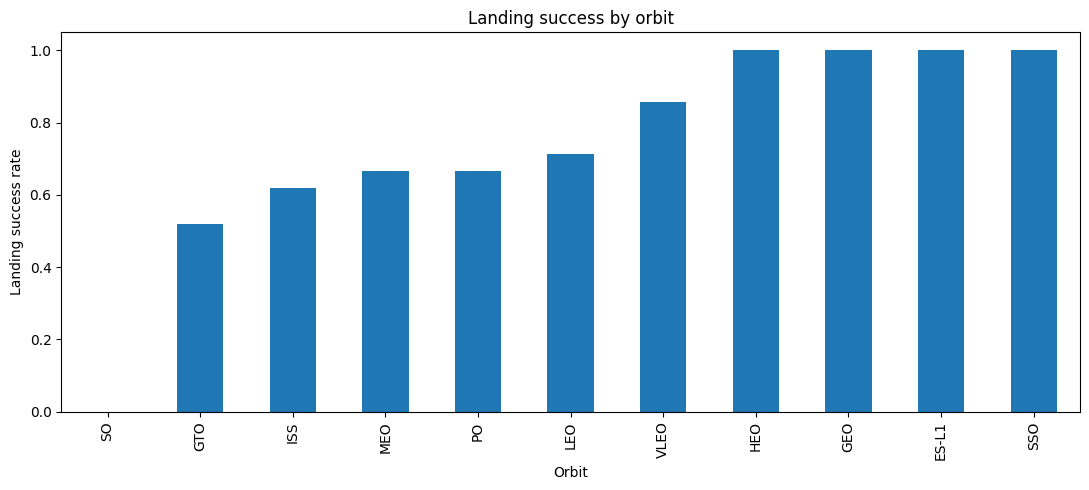

In [2]:
def savefig(name):
    plt.tight_layout();plt.savefig(O/name,dpi=180,bbox_inches='tight');plt.show()
for x,y,hue,name in [(flight,site,'Class','flight_vs_site.png'),(payload,site,'Class','payload_vs_site.png'),(flight,orb,'Class','flight_vs_orbit.png'),(payload,orb,'Class','payload_vs_orbit.png')]:
    plt.figure(figsize=(11,5));sns.scatterplot(data=df,x=x,y=y,hue=hue);plt.title(f'{x} vs {y}');savefig(name)
plt.figure(figsize=(11,5));df.groupby(orb)['Class'].mean().sort_values().plot.bar();plt.ylabel('Landing success rate');plt.title('Landing success by orbit');savefig('success_by_orbit.png')

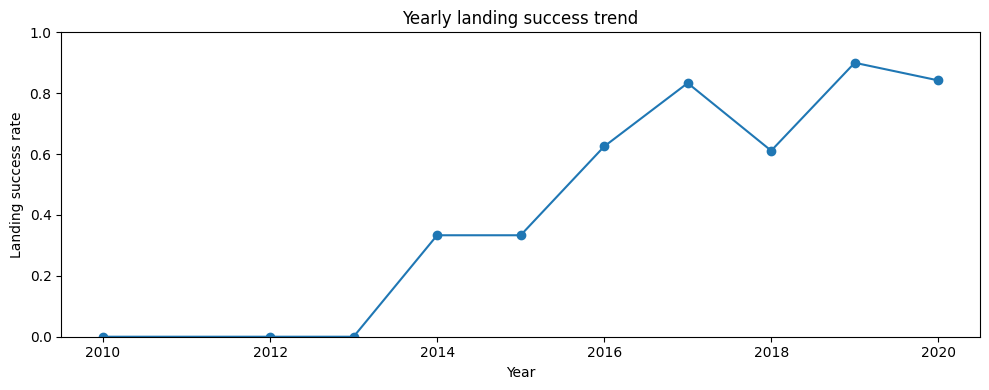

Observations: 90
Overall landing success: 0.667


In [3]:
datecol='Date' if 'Date' in df else 'Date'
df['Year']=pd.to_datetime(df[datecol],utc=True,errors='coerce').dt.year
trend=df.dropna(subset=['Year']).groupby('Year')['Class'].mean()
plt.figure(figsize=(10,4));trend.plot(marker='o');plt.ylim(0,1);plt.ylabel('Landing success rate');plt.title('Yearly landing success trend');savefig('yearly_trend.png')
print('Observations:',len(df));print('Overall landing success:',round(df['Class'].mean(),3))